# Stitching parameter search: AF and minimum focal-region size

Analyse `hpc_params1_diagnostics` without rerunning matching. The archived grid
has **three AF cutoffs (0.01, 0.03, 0.05)**, four minimum sizes (1, 100, 300,
1000 inference sites), and three simulation cohorts (300, 3000, 10000 diploid
individuals). Every plot has one column per sample size. AF-panel plots have
one row per AF; metric-panel plots have one row per metric/reference.

This adapts pt6's haplotype means, hourglass SEMs, population groups, switch
partitions, sample alignment, ARG metrics and posterior mutation-age rules.
Derived AF replaces AC throughout. The archived config/manifest, rather than
the current mutable pipeline config, define this analysis. Generated tables,
dates and PNGs are cached in `data/ch5/hpc_params1_diagnostics/for_plots`.

In [1]:
import logging
import pathlib

import IPython.display as ipython_display
import numpy as np
import pandas as pd

from ch5 import nb_plot, nb_utils

repository_dir = pathlib.Path.cwd()
logger = logging.getLogger(__name__)

/Users/duncan/work/dphil-analysis/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
repository_dir = pathlib.Path.cwd()
config_path = {
    "data_dir": repository_dir / "data/ch5/hpc_params1_diagnostics",
    "cache_subdir": "for_plots",
    "workers": None,
    "helper_threads": 1,
    "mutation_rate": 2.35e-08,
    "followup_minimum_sizes": [1000, 2000, 3000, 5000, 10000],
    "dating": {
        "post_process": {"split_ultimate": True, "erase_flanks": True},
        "preprocess": {"delete_intervals": [], "split_disjoint": True},
        "estimation": {
            "method": "variational_gamma",
            "time_units": "generations",
            "set_metadata": True,
            "progress": False,
            "singletons_phased": True,
        },
    },
    "frequency_bins": {
        "cutoffs": [0.01, 0.5],
        "labels": ["DAF < 0.01", "0.01 ≤ DAF < 0.5", "DAF ≥ 0.5"],
    },
}
config_path["base_dir"] = repository_dir
config = nb_utils.paramsearch_load_config(config_path)
manifest = config["manifest"]
datasets = manifest["datasets"]
experiment = config["experiment"]
af_cutoffs = sorted(experiment["af_cutoff"])
minimum_sizes = sorted(experiment["min_focal_region_size"])
output_dir = config["cache_dir"]
cutoff_colors = dict(zip(af_cutoffs, ["#0072B2", "#D55E00", "#009E73"], strict=True))
minimum_colors = dict(
    zip(minimum_sizes, ["#0072B2", "#009E73", "#E69F00", "#CC79A7"], strict=True)
)
logging.basicConfig(level=logging.INFO, format="%(message)s")

## Pipeline changes and archived run checks

Recent `tsinfer-match-eval` changes replace the old per-seed/mismatch logic
with exact seeded extension, then a greedy minimum-run cover of touching
interval unions. **Minimum size filters whole connected unions**, not the
individual copying runs inside them. Ancestors qualify when cohort-derived
seed frequency is **≤ af_cutoff**. Each complementary gap gets a fresh HMM
likelihood calculation. Reference topology is retained between gap calls;
this supplies no likelihood boundary condition. Seams can therefore add
switches even when no mismatches are permitted in focal extension.

The diagnostics target now reconstructs masks and exports per-haplotype
comparisons, interval lengths, population joins and portable tree paths.
Parallelism/prepared paths and bulk edge insertion change the execution.
The latest revision also changes assembly and retains reference topology.
Diagnostic-time code revisions are printed below; the manifest explicitly
cautions that these do not establish which code produced older saved trees.
No performance benchmark accompanies this archive, so focal coverage is only
a proxy for HMM work avoided; this analysis cannot establish runtime speedup.

In [3]:
summary = pd.read_csv(config["data_dir"] / manifest["tables"]["run_summary"])
populations = pd.read_csv(config["data_dir"] / manifest["tables"]["sample_populations"])
grid_keys = ["dataset", "af_cutoff", "min_focal_region_size"]
expected = pd.MultiIndex.from_product(
    [[item["name"] for item in datasets], af_cutoffs, minimum_sizes], names=grid_keys
)
assert not summary.duplicated(grid_keys).any()
assert summary.set_index(grid_keys).index.sort_values().equals(expected.sort_values())
for dataset in datasets:
    rows = summary.loc[summary.dataset.eq(dataset["name"])]
    cohort = populations.loc[populations.dataset.eq(dataset["name"])]
    assert rows.num_haplotypes.eq(len(cohort)).all()
    assert rows.num_samples.eq(cohort.sample_id.nunique()).all()
    assert rows.unmatched_sites_mean.eq(0).all()
    assert rows.excluded_sites_mean.eq(0).all()
    for method in ["full", "stitched"]:
        category_columns = [
            f"{method}_{category}_switches_mean"
            for category in ["focal", "gap", "seam"]
        ]
        np.testing.assert_allclose(
            rows[category_columns].sum(axis=1), rows[f"{method}_switches_mean"]
        )
revisions = manifest["diagnostics_time_versions"]["revisions"]
ipython_display.display(
    pd.DataFrame(
        [
            {
                "component": name,
                "diagnostic_time_commit": item["commit"],
                "status": item["status"],
            }
            for name, item in revisions.items()
        ]
    )
)
check_columns = grid_keys + [
    "num_haplotypes",
    "num_samples",
    "empty_focal_haplotypes",
    "empty_gap_haplotypes",
    "zero_full_switch_haplotypes",
]
ipython_display.display(summary[check_columns])

,component,diagnostic_time_commit,status
0,pipeline,c29c7f17944bea309640e37fbbe74db00fac1e4d,"[?? .ipynb_checkpoints/, ?? config.yaml.hpc_pa..."
1,tsinfer,6beae28f54acd6e657062b32a294c889496066c5,[]


,dataset,af_cutoff,min_focal_region_size,num_haplotypes,num_samples,empty_focal_haplotypes,empty_gap_haplotypes,zero_full_switch_haplotypes
0,out_of_africa_n300_10mbp_error,0.01,1,600,300,0,0,0
1,out_of_africa_n300_10mbp_error,0.01,100,600,300,0,0,0
2,out_of_africa_n300_10mbp_error,0.01,300,600,300,0,0,0
3,out_of_africa_n300_10mbp_error,0.01,1000,600,300,0,0,0
4,out_of_africa_n300_10mbp_error,0.03,1,600,300,0,0,0
5,out_of_africa_n300_10mbp_error,0.03,100,600,300,0,0,0
6,out_of_africa_n300_10mbp_error,0.03,300,600,300,0,0,0
7,out_of_africa_n300_10mbp_error,0.03,1000,600,300,0,0,0
8,out_of_africa_n300_10mbp_error,0.05,1,600,300,0,0,0
9,out_of_africa_n300_10mbp_error,0.05,100,600,300,0,0,0


## Site-based minimum sizes in kb

Bars show the genome-wide mean physical equivalent of each tested site-count
threshold, using the same density conversion as `min_region_size_kb`:
`minimum_sites × (last_position − first_position) / num_sites / 1000`.
These are mean equivalents, not the distribution of local window lengths:
local site density varies. AF does not affect this conversion.

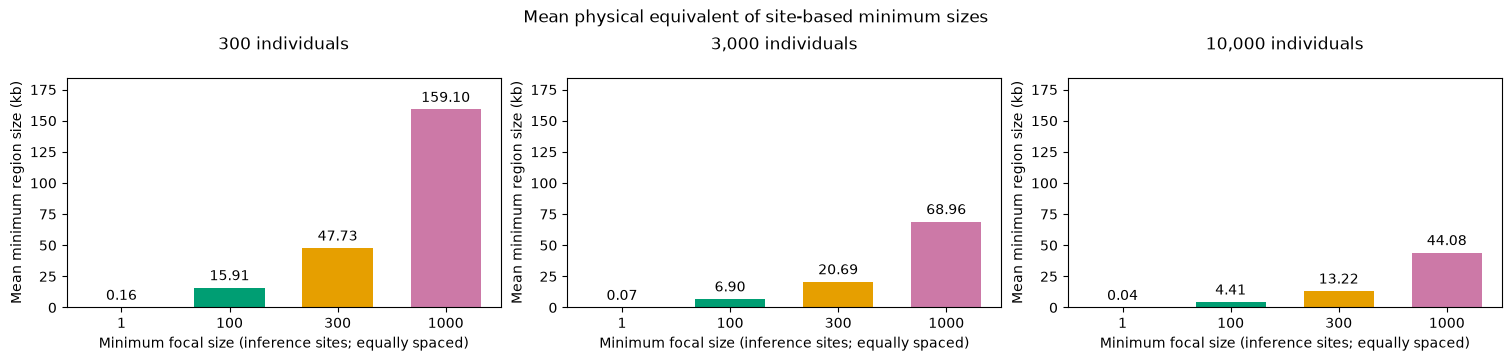

In [5]:
if __name__ == "__main__":
    nb_plot.parameter_grid_save_figure(
        nb_plot.minimum_size_kb_plot(
            config=config,
            datasets=datasets,
            minimum_colors=minimum_colors,
            minimum_sizes=minimum_sizes,
            output_dir=output_dir,
            plot_bar_width=0.65,
            plot_panel_height=3.5,
            plot_panel_width=5,
            plot_range_margin=0.08,
            populations=populations,
            dpi=100,
            show_top_spine=True,
            show_right_spine=True,
        ),
        "minimum_size_kb",
        output_dir=output_dir,
    )

## Extra switches vs minimum focal size

Percent changes are calculated per haplotype then averaged, rather than from
the ratio of pooled switch counts. Hourglasses show mean ± one SEM. These
describe haplotype variation within a single simulation, not independent
simulation replicates; the paired haplotypes' dependence is not accounted for.

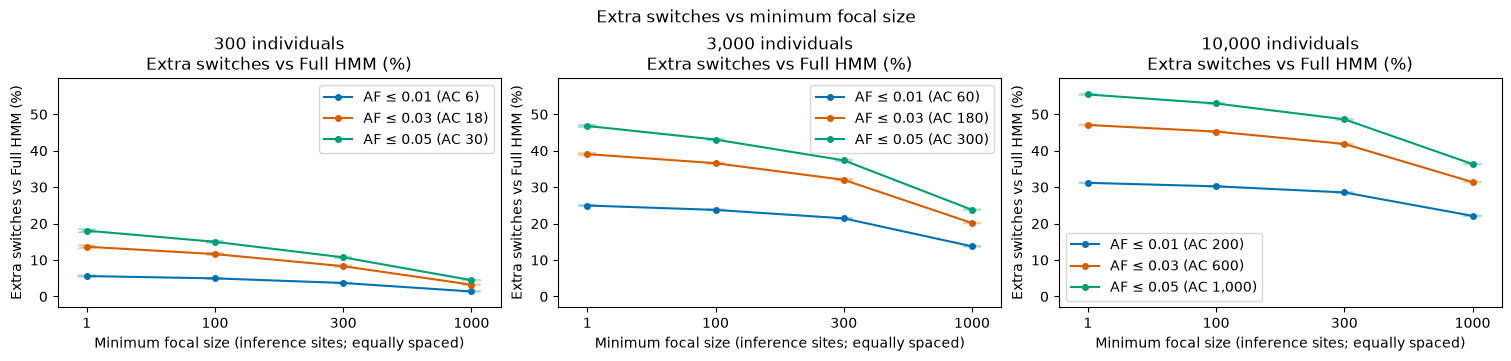

In [5]:
if __name__ == "__main__":
    fig = nb_plot.metric_lines(
        summary,
        {"switch_increase_percentage": "Extra switches vs Full HMM (%)"},
        "Extra switches vs minimum focal size",
        summary_statistics=True,
        af_cutoffs=af_cutoffs,
        cutoff_colors=cutoff_colors,
        datasets=datasets,
        minimum_sizes=minimum_sizes,
        plot_hourglass_alpha=0.3,
        plot_hourglass_width=0.07,
        plot_line_width=1.5,
        plot_marker_size=4,
        plot_panel_height=3.5,
        plot_panel_width=5,
        plot_range_margin=0.08,
        populations=populations,
        dpi=100,
        show_top_spine=True,
        show_right_spine=True,
    )
    nb_plot.parameter_grid_save_figure(fig, "extra_switches", output_dir=output_dir)

## Focal region distributions

Coverage uses the diagnostic physical analysis extent (first to last observed
inference position, approximately 0.081–10 Mb), not the 64 Mb chromosome
length retained in raw trees. African = YRI; Non-African pools CEU and CHB.
Coverage axes zoom to the displayed population means plus a margin.

Lengths count inference sites in maximal connected focal components. Only
**minimum size 1** is shown; dashed vertical lines locate every tested size.
The histogram has a directly editable `num_bins` argument below. Densities
reproduce pt6's reflected Scott KDE on all intervals, including the tails,
and are scaled to count per bin. Each AF row shares bins across sample sizes.
The display ends at the pooled 99th percentile, extended to include all size
thresholds; legends report omitted tail counts. Lossless integer-length counts
are cached so changing bins does not require rereading the 4 GB source CSV.
Count axes scale independently because the cohorts differ greatly in size.

In [6]:
if __name__ == "__main__":
    population_coverage = nb_utils.population_summary(config)
    lengths = nb_utils.paramsearch_length_counts(config)

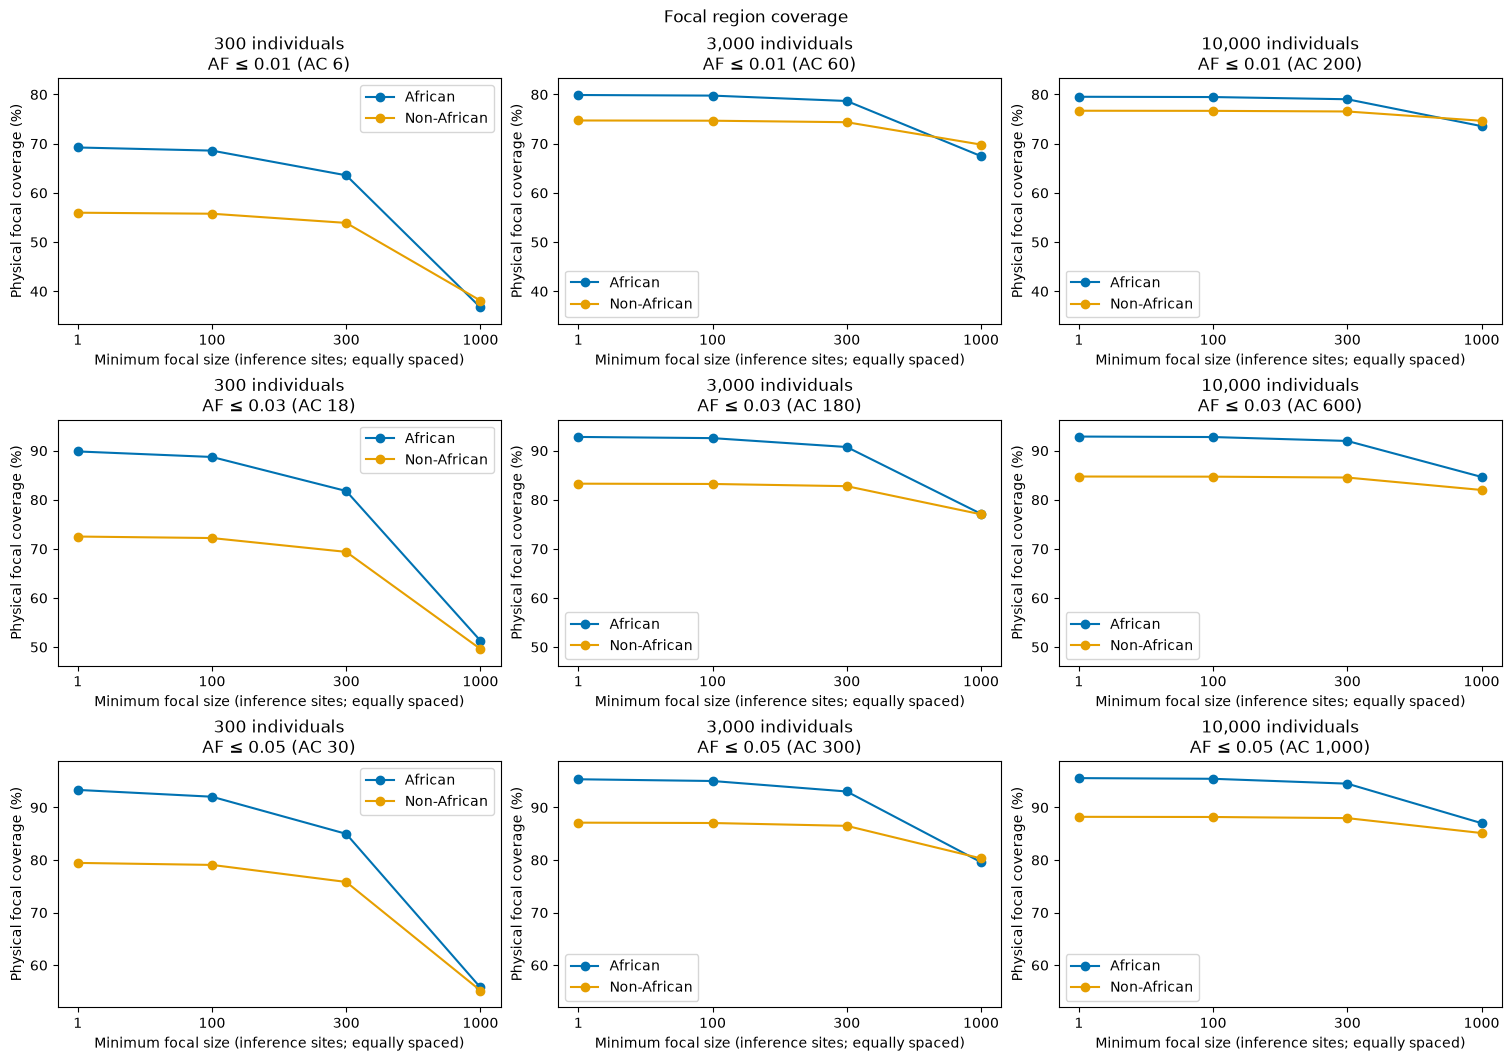

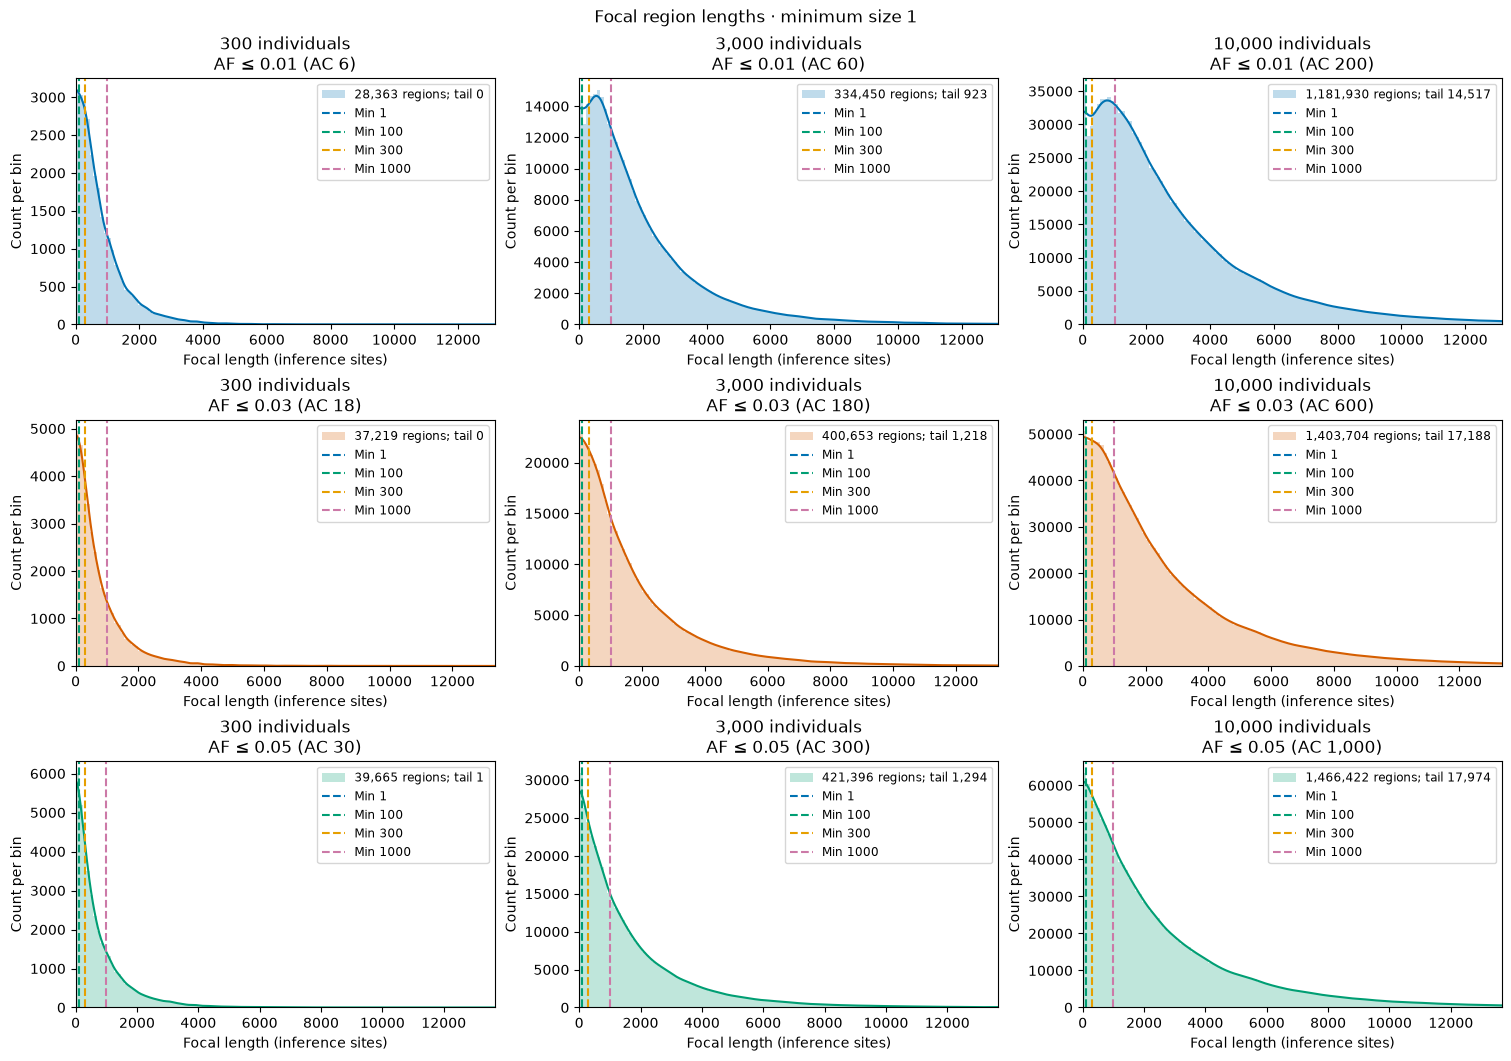

In [7]:
if __name__ == "__main__":
    nb_plot.parameter_grid_save_figure(
        nb_plot.focal_coverage(
            af_cutoffs=af_cutoffs,
            datasets=datasets,
            minimum_sizes=minimum_sizes,
            plot_panel_height=3.5,
            plot_panel_width=5,
            plot_population_colors={"African": "#0072B2", "Non-African": "#E69F00"},
            plot_range_margin=0.08,
            population_coverage=population_coverage,
            populations=populations,
            dpi=100,
            show_top_spine=True,
            show_right_spine=True,
        ),
        "focal_coverage",
        output_dir=output_dir,
    )
    nb_plot.parameter_grid_save_figure(
        nb_plot.focal_lengths(
            num_bins=120,
            af_cutoffs=af_cutoffs,
            cutoff_colors=cutoff_colors,
            datasets=datasets,
            lengths=lengths,
            minimum_colors=minimum_colors,
            minimum_sizes=minimum_sizes,
            plot_baseline_minimum=1,
            plot_histogram_alpha=0.25,
            plot_kde_grid_size=512,
            plot_length_display_quantile=0.99,
            plot_panel_height=3.5,
            plot_panel_width=5,
            populations=populations,
            dpi=100,
            show_top_spine=True,
            show_right_spine=True,
        ),
        "focal_lengths",
        output_dir=output_dir,
    )

## Gap distributions

Density curves only, coloured by minimum region size. Matching dashed lines
show each distribution's median. KDEs use all gap lengths with reflection at
zero. Each row shares the pooled 99th-percentile display range and reports
tail fractions. The bar chart below separately counts one-site gaps.

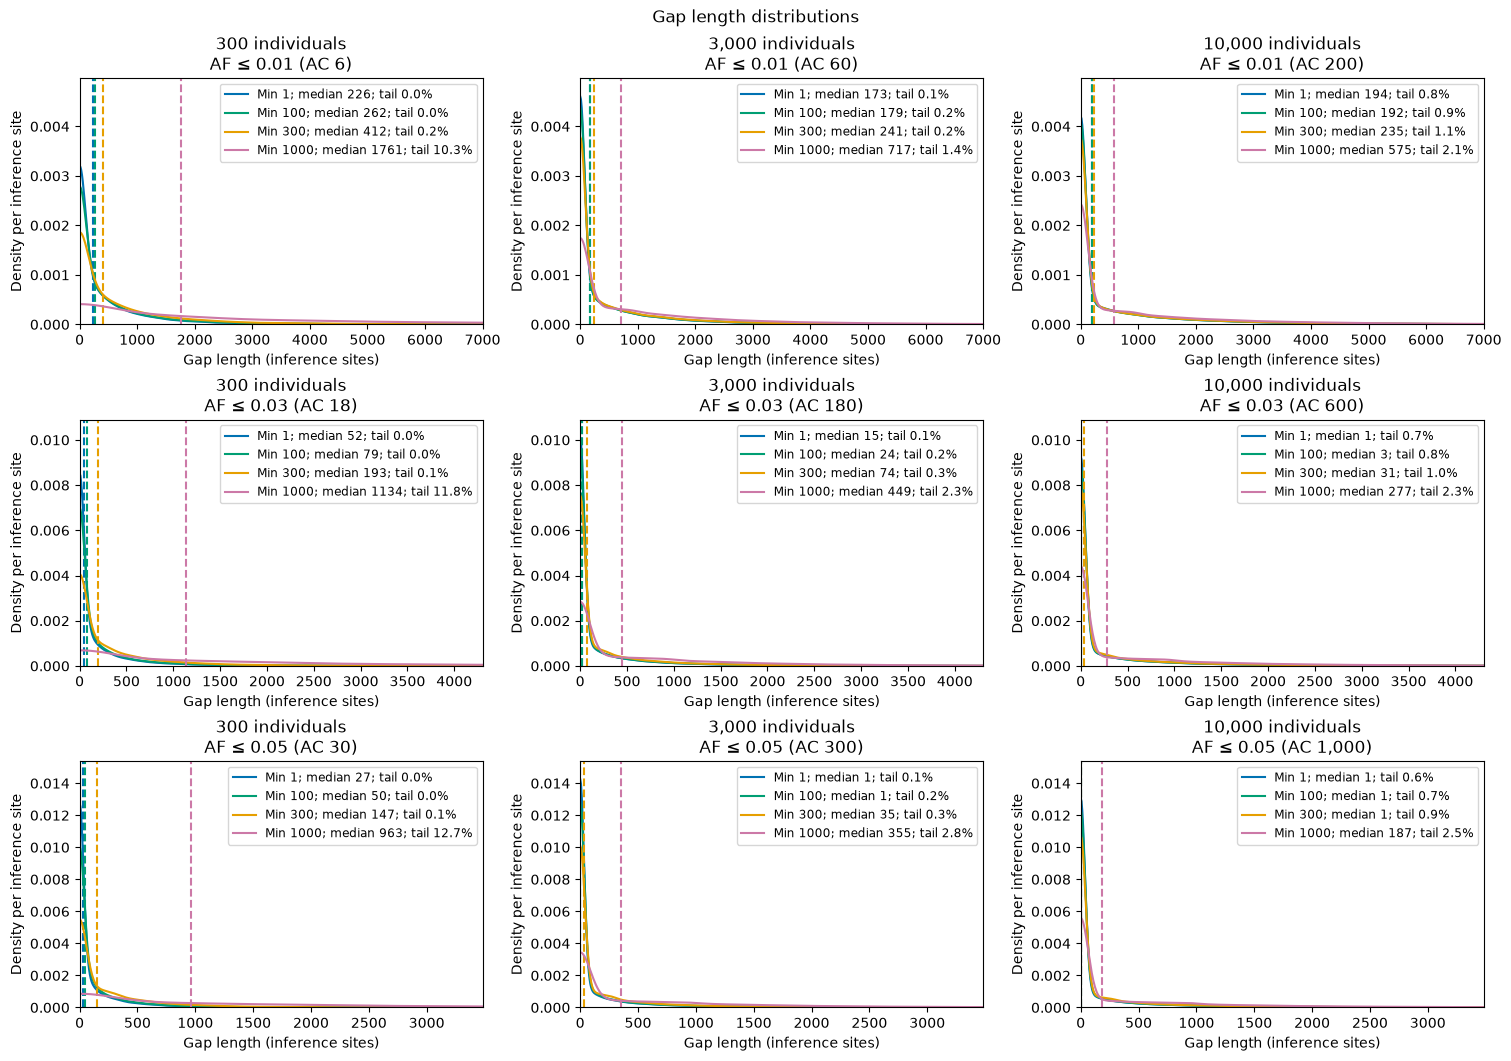

In [8]:
if __name__ == "__main__":
    nb_plot.parameter_grid_save_figure(
        nb_plot.gap_lengths(
            af_cutoffs=af_cutoffs,
            datasets=datasets,
            lengths=lengths,
            minimum_colors=minimum_colors,
            plot_kde_grid_size=512,
            plot_length_display_quantile=0.99,
            plot_line_width=1.5,
            plot_panel_height=3.5,
            plot_panel_width=5,
            plot_range_margin=0.08,
            populations=populations,
            dpi=100,
            show_top_spine=True,
            show_right_spine=True,
        ),
        "gap_lengths",
        output_dir=output_dir,
    )

### One-site gaps

Bars count gap regions containing exactly one inference site, pooled across
all haplotypes. Labels give their percentage of **all gap regions** for that
dataset/AF/minimum combination, including the full length-distribution tails.
Each AF has a row; sample sizes have columns; bars span all tested minima.

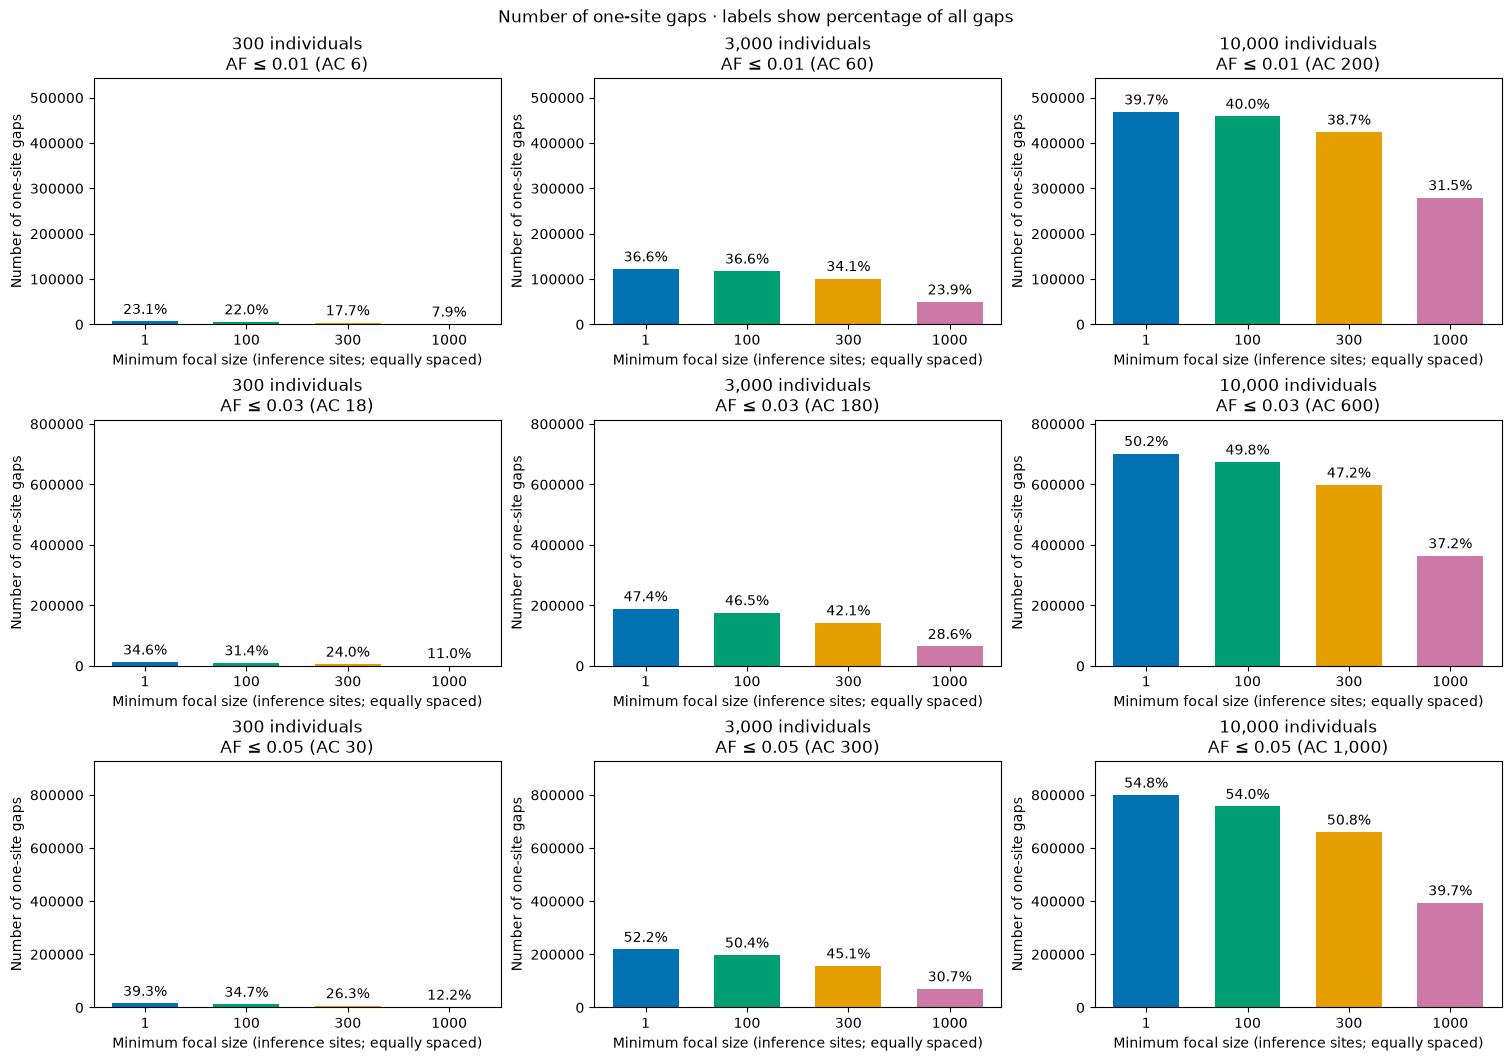

In [6]:
if __name__ == "__main__":
    nb_plot.parameter_grid_save_figure(
        nb_plot.one_site_gaps(
            af_cutoffs=af_cutoffs,
            datasets=datasets,
            grid_keys=grid_keys,
            lengths=lengths,
            minimum_colors=minimum_colors,
            minimum_sizes=minimum_sizes,
            output_dir=output_dir,
            plot_bar_width=0.65,
            plot_panel_height=3.5,
            plot_panel_width=5,
            plot_range_margin=0.08,
            populations=populations,
            dpi=100,
            show_top_spine=True,
            show_right_spine=True,
        ),
        "one_site_gaps",
        output_dir=output_dir,
    )

## Switch composition

Raw mean switches partition into within-focal, within-gap and seam switches.
Full HMM has one baseline bar partitioned using minimum size 1 for that AF.
Each stitched bar uses its own mask. The Full HMM total is invariant under
these partitions; raising the minimum changes its categories, not its path.

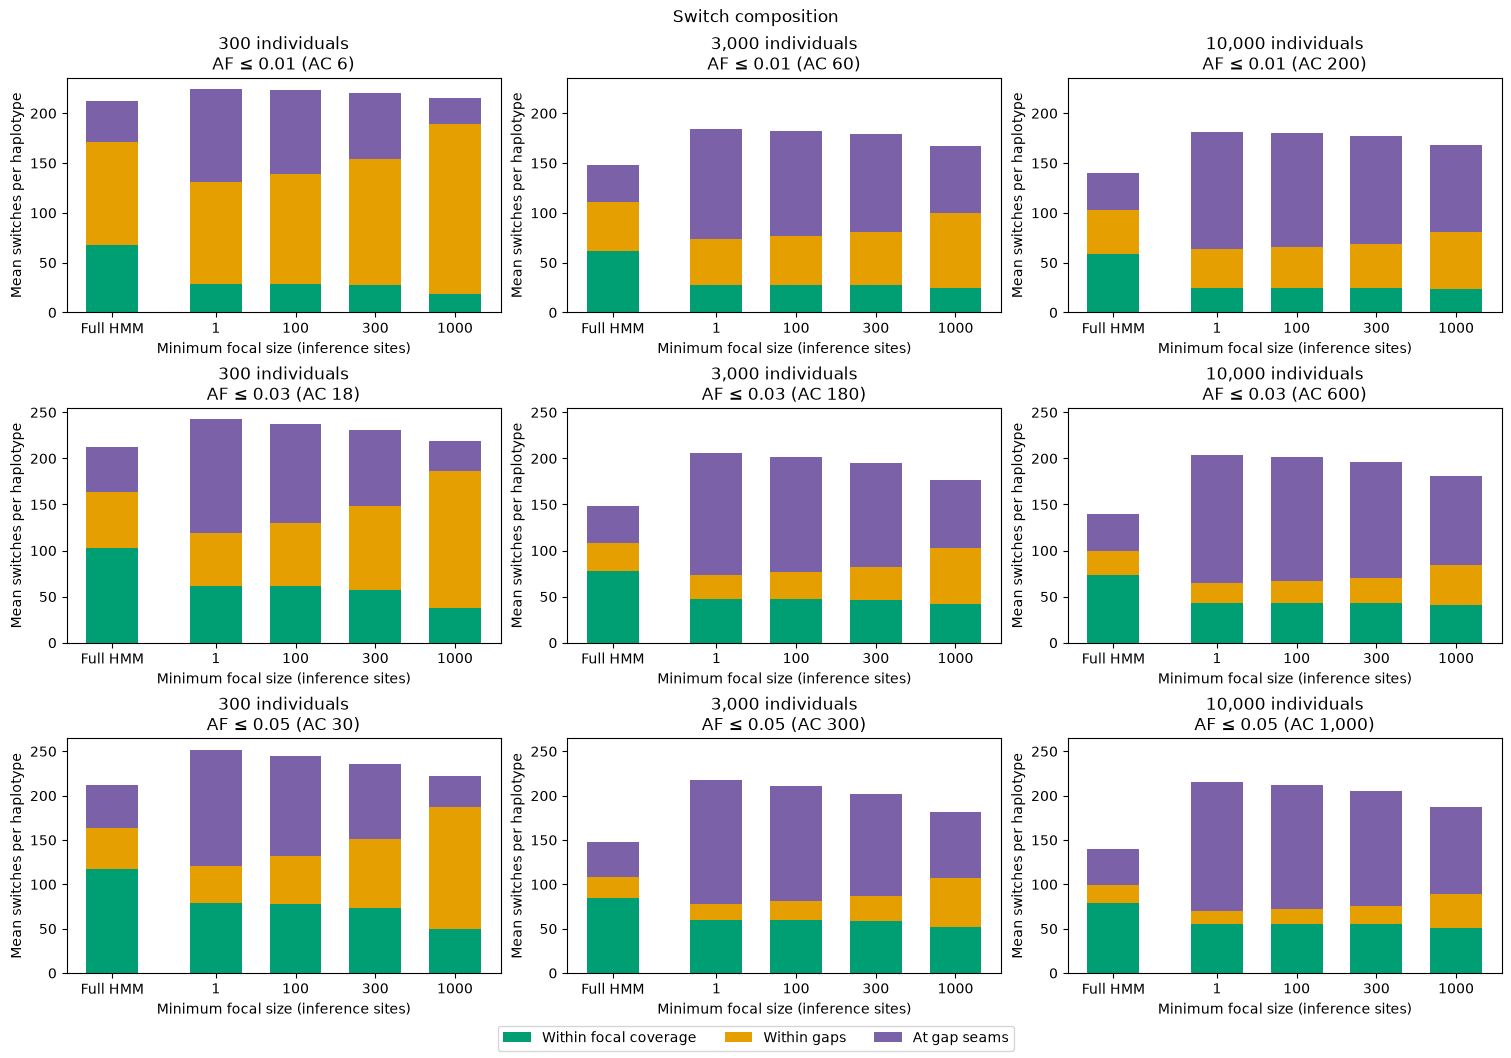

In [9]:
if __name__ == "__main__":
    nb_plot.parameter_grid_save_figure(
        nb_plot.parameter_grid_switch_composition(
            af_cutoffs=af_cutoffs,
            datasets=datasets,
            minimum_sizes=minimum_sizes,
            plot_bar_width=0.65,
            plot_baseline_minimum=1,
            plot_panel_height=3.5,
            plot_panel_width=5,
            plot_switch_categories=["focal", "gap", "seam"],
            plot_switch_colors=["#009E73", "#E69F00", "#7B61A8"],
            plot_switch_labels=["Within focal coverage", "Within gaps", "At gap seams"],
            populations=populations,
            summary=summary,
            dpi=100,
            show_top_spine=True,
            show_right_spine=True,
        ),
        "switch_composition",
        output_dir=output_dir,
    )

## Parent agreement

Focal and gap regions occupy separate rows, keeping sample sizes in columns.
Each region's y range covers the observed mean ± SEM across **all AF values
and sample sizes**, plus a margin. The denominator is the evaluated inference
sites within that region, followed by an equal-weight haplotype mean.

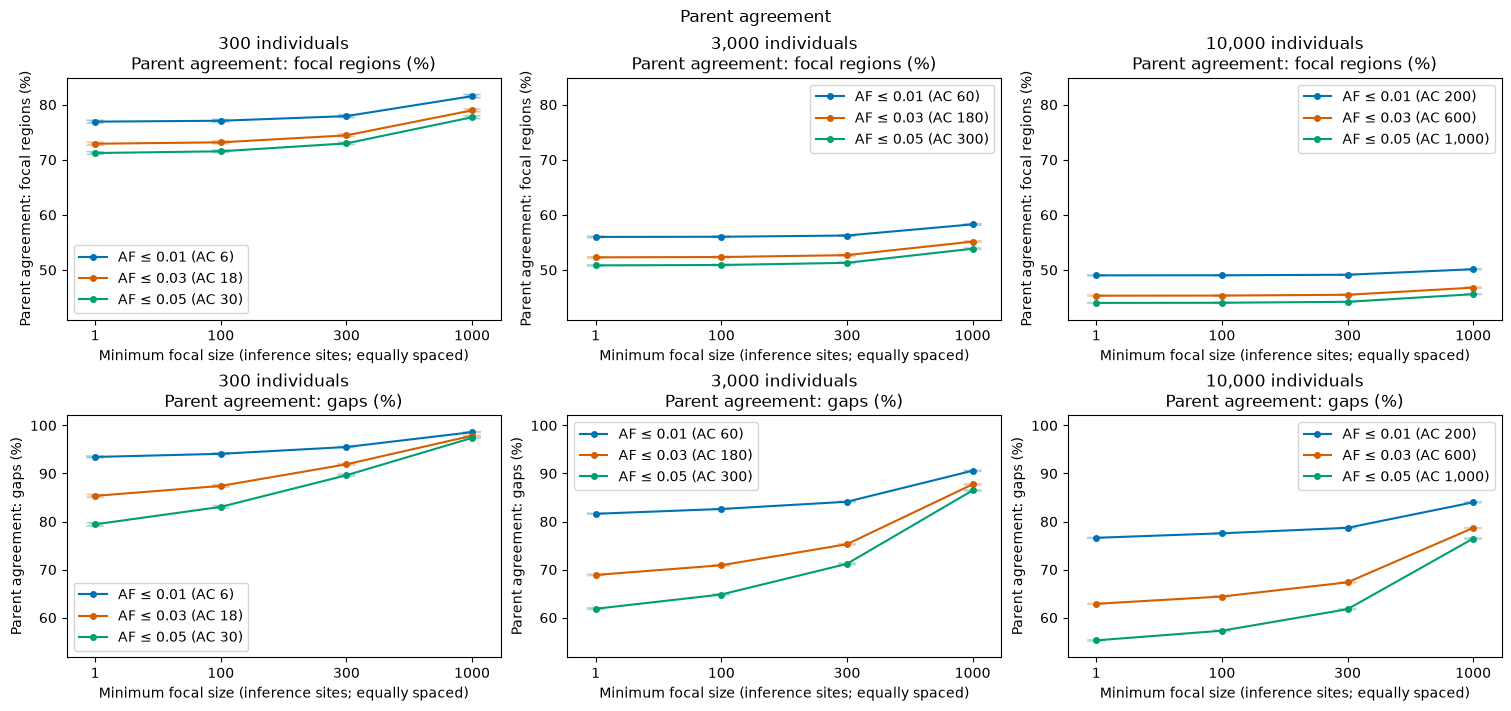

In [10]:
if __name__ == "__main__":
    metrics = {
        "focal_agreement_percentage": "Parent agreement: focal regions (%)",
        "gap_agreement_percentage": "Parent agreement: gaps (%)",
    }
    nb_plot.parameter_grid_save_figure(
        nb_plot.metric_lines(
            summary,
            metrics,
            "Parent agreement",
            summary_statistics=True,
            af_cutoffs=af_cutoffs,
            cutoff_colors=cutoff_colors,
            datasets=datasets,
            minimum_sizes=minimum_sizes,
            plot_hourglass_alpha=0.3,
            plot_hourglass_width=0.07,
            plot_line_width=1.5,
            plot_marker_size=4,
            plot_panel_height=3.5,
            plot_panel_width=5,
            plot_range_margin=0.08,
            populations=populations,
            dpi=100,
            show_top_spine=True,
            show_right_spine=True,
        ),
        "parent_agreement",
        output_dir=output_dir,
    )

## Tree sequence comparisons

Percentage change = 100 × (stitched / Full HMM − 1), using raw saved edge/tree
counts including retained reference ancestry and chromosome extent. Edge and
tree metrics occupy rows to preserve one column per sample size.

**Load completed comparisons only. Do not calculate missing metrics.** Large
tree comparisons were stopped at the user's request. Missing runs are left
blank, with NaNs preventing lines from connecting across missing settings.
The coverage table below records what was completed. Existing comparisons
align biological sample identities and restrict both trees to the same
diagnostic analysis window.
For practical runtime at 20,000 haplotypes, `ch5.nb_utils.BitsetCladeMap` substitutes
exact integer bitsets for tscompare's frozenset clade iterator inside each
worker. The tscompare span matching and ARF/TPR formulas are unchanged;
equality is tested against its reference implementation, including unary
ancestry, missing spans and sample sets larger than 64 haplotypes.

,sum,count
dataset,,
out_of_africa_n10000_10mbp_error,0,13
out_of_africa_n3000_10mbp_error,1,13
out_of_africa_n300_10mbp_error,13,13


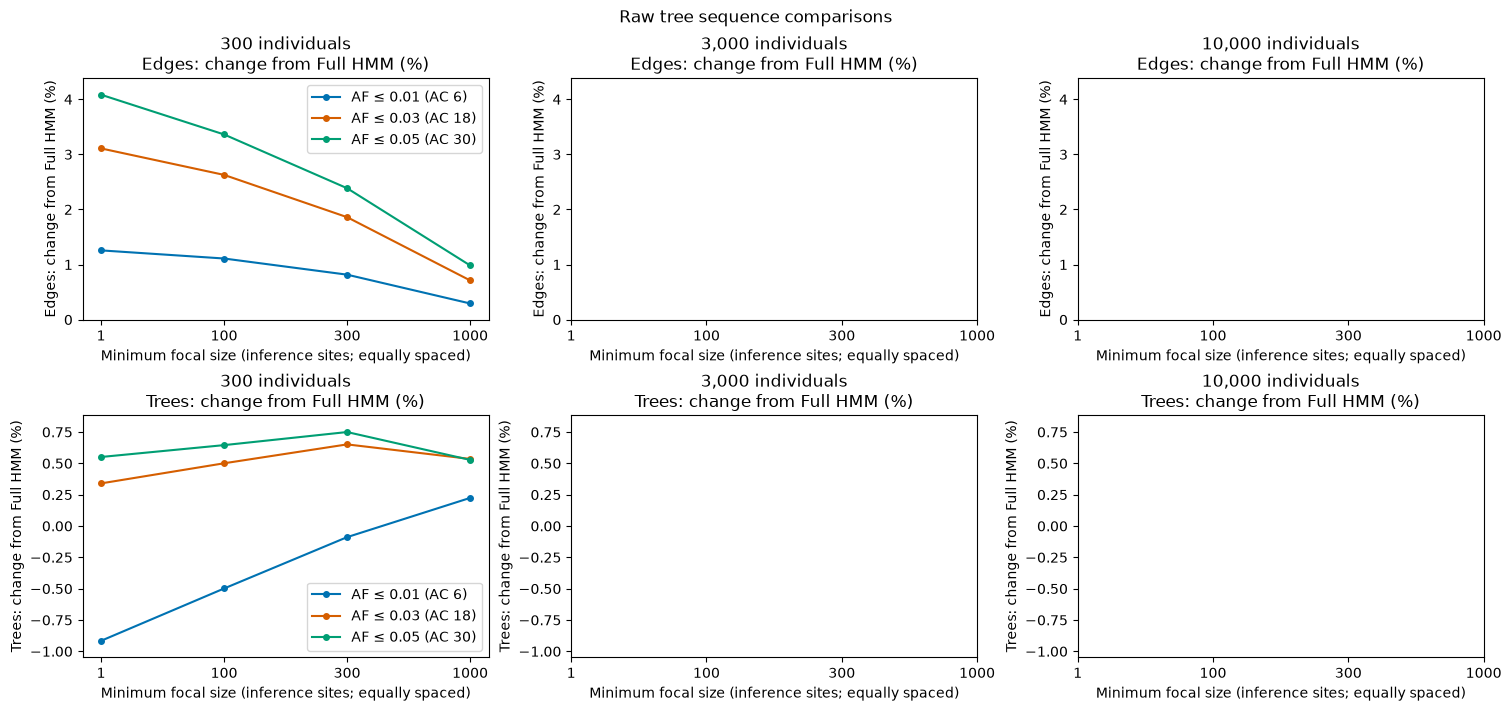

In [11]:
if __name__ == "__main__":
    completed_metrics = []
    metric_inventory = []
    for job in nb_utils.tree_jobs(config):
        path = output_dir / "tree_metrics" / f"{job.key}.csv"
        signature = nb_utils.input_signature(
            [
                job.raw_path,
                job.root / job.dataset["truth"],
                job.root / job.dataset["full_hmm"],
            ],
            {},
        )
        cached = nb_utils.cached_table(path, signature)
        metric_inventory.append({**job.labels, "completed": cached is not None})
        if cached is not None:
            completed_metrics.append(cached)
    tree_metrics = pd.concat(completed_metrics, ignore_index=True)
    tree_metrics.to_csv(output_dir / "available_tree_metrics.csv", index=False)
    metric_inventory = pd.DataFrame(metric_inventory)
    metric_inventory.to_csv(output_dir / "tree_metric_inventory.csv", index=False)
    ipython_display.display(
        metric_inventory.groupby("dataset").completed.agg(["sum", "count"])
    )
    metrics = {
        "edges_change_percentage": "Edges: change from Full HMM (%)",
        "trees_change_percentage": "Trees: change from Full HMM (%)",
    }
    nb_plot.parameter_grid_save_figure(
        nb_plot.metric_lines(
            tree_metrics,
            metrics,
            "Raw tree sequence comparisons",
            af_cutoffs=af_cutoffs,
            cutoff_colors=cutoff_colors,
            datasets=datasets,
            minimum_sizes=minimum_sizes,
            plot_hourglass_alpha=0.3,
            plot_hourglass_width=0.07,
            plot_line_width=1.5,
            plot_marker_size=4,
            plot_panel_height=3.5,
            plot_panel_width=5,
            plot_range_margin=0.08,
            populations=populations,
            dpi=100,
            show_top_spine=True,
            show_right_spine=True,
        ),
        "tree_counts",
        output_dir=output_dir,
    )

## ARG metrics vs. Full HMM

`tscompare.haplotype_arf(stitched, full)` measures unsupported stitched node
span (ARF, lower is better) and recovered Full HMM node span (TPR, higher is
better). Sample IDs and ploidy indices determine sample order; simplification
retains unary nodes. Full HMM agreement is distinct from biological accuracy.

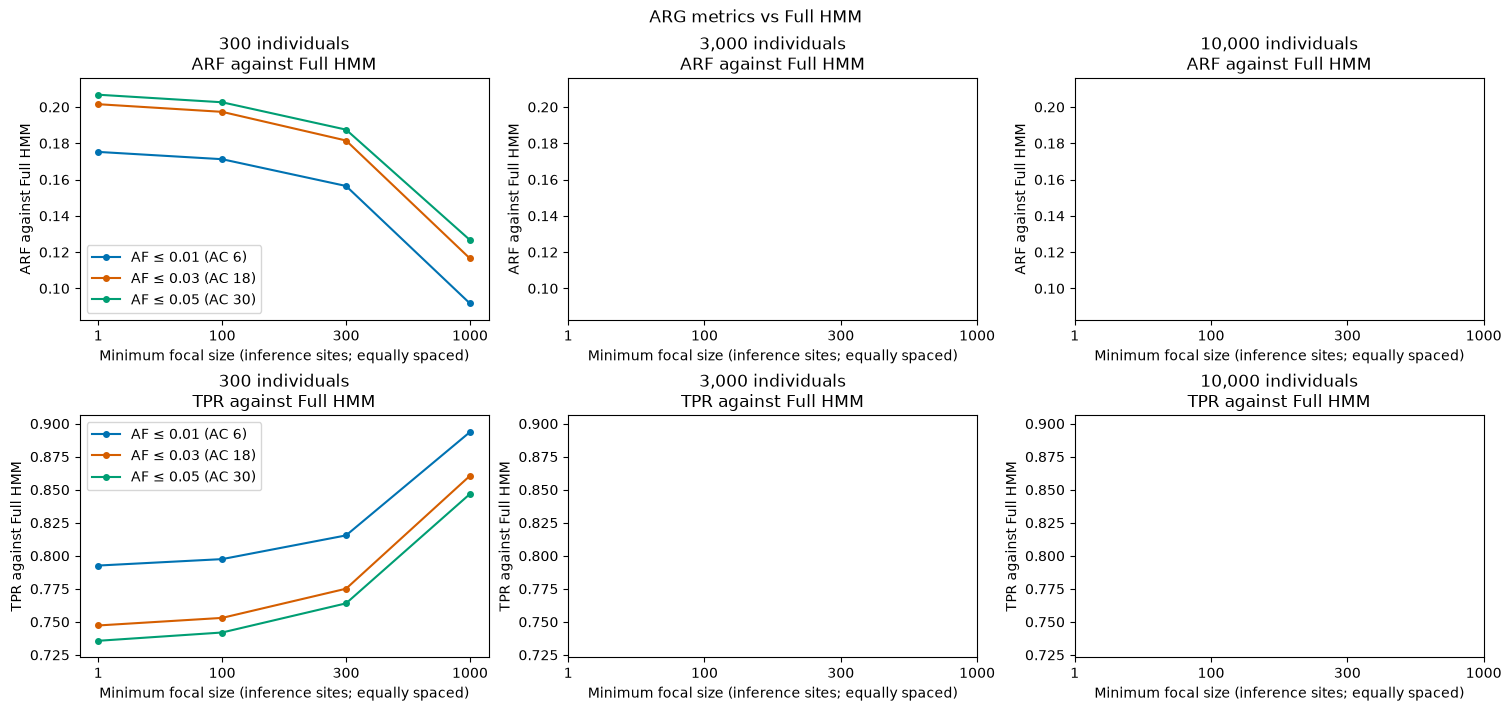

In [12]:
if __name__ == "__main__":
    metrics = {"full_arf": "ARF against Full HMM", "full_tpr": "TPR against Full HMM"}
    nb_plot.parameter_grid_save_figure(
        nb_plot.metric_lines(
            tree_metrics,
            metrics,
            "ARG metrics vs Full HMM",
            af_cutoffs=af_cutoffs,
            cutoff_colors=cutoff_colors,
            datasets=datasets,
            minimum_sizes=minimum_sizes,
            plot_hourglass_alpha=0.3,
            plot_hourglass_width=0.07,
            plot_line_width=1.5,
            plot_marker_size=4,
            plot_panel_height=3.5,
            plot_panel_width=5,
            plot_range_margin=0.08,
            populations=populations,
            dpi=100,
            show_top_spine=True,
            show_right_spine=True,
        ),
        "arg_vs_full",
        output_dir=output_dir,
    )

## ARG metrics vs true TS

Same alignment and window rules as above, with truth's VCF sample identity
mapping. Each panel includes the Full HMM baseline as a distinct category.
ARF measures inferred span unsupported by truth; TPR measures true span
recovered. Baseline repetition connects each AF curve to the same Full HMM.
As in pt6, these are raw inferred trees: their node-time units are unknown,
whereas truth uses generations. ARF uses maximum matching span regardless
of time. tscompare uses node times to break equal-span clade-match ties, so
the inverse matching used by TPR also depends on that tie-breaking rule.

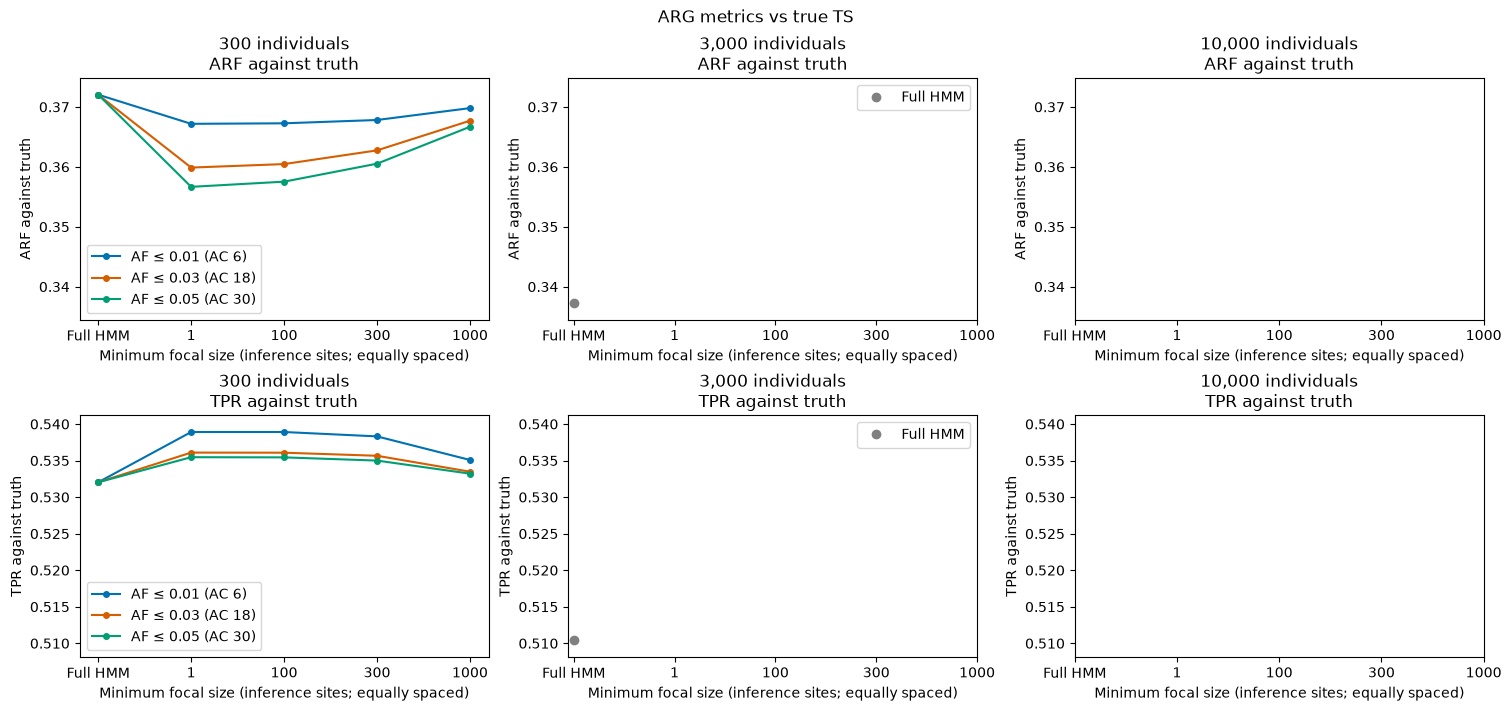

In [13]:
if __name__ == "__main__":
    metrics = {"truth_arf": "ARF against truth", "truth_tpr": "TPR against truth"}
    nb_plot.parameter_grid_save_figure(
        nb_plot.metric_lines(
            tree_metrics,
            metrics,
            "ARG metrics vs true TS",
            baseline=True,
            af_cutoffs=af_cutoffs,
            cutoff_colors=cutoff_colors,
            datasets=datasets,
            minimum_sizes=minimum_sizes,
            plot_hourglass_alpha=0.3,
            plot_hourglass_width=0.07,
            plot_line_width=1.5,
            plot_marker_size=4,
            plot_panel_height=3.5,
            plot_panel_width=5,
            plot_range_margin=0.08,
            populations=populations,
            dpi=100,
            show_top_spine=True,
            show_right_spine=True,
        ),
        "arg_vs_truth",
        output_dir=output_dir,
    )

## Mutation age correlations

Date the archived inferred trees **without restoring variants**. As in pt6,
post-process, restrict the window, split disjoint nodes, and use tsdate's
variational-gamma estimates with mutation rate 2.35 × 10⁻⁸ per bp/generation
(the simulation provenance). Dates are cached per input/settings/code signature.

Compare posterior **mutation means** (`metadata['mn']`) with simulated event
times or Full HMM posterior means. For each sample size, take **one common
intersection across truth, Full HMM and all twelve stitched runs**, using
position plus ancestral/derived states. Exclude zero/multiple-mutation sites
and nonfinite ages. Both reference panels use exactly this same set. Pearson r
is calculated on ages in generations, before any transformation. Counts below
show how many mutations survive. No heatmap plots are produced.

In [14]:
if __name__ == "__main__":
    dated_runs = nb_utils.run_tree_jobs(config, "dating")
    age_correlations = nb_utils.paramsearch_mutation_correlations(config, dated_runs)
    counts = age_correlations.groupby(
        ["dataset", "reference_method", "frequency_bin"]
    ).matched_mutations.agg(["min", "max"])
    assert counts["min"].eq(counts["max"]).all()
    ipython_display.display(counts)

dating: completed out_of_africa_n300_10mbp_error_full_hmm (1/39)


dating: completed out_of_africa_n3000_10mbp_error_af_0.03_min_1 (2/39)


dating: completed out_of_africa_n3000_10mbp_error_af_0.03_min_100 (3/39)


dating: completed out_of_africa_n3000_10mbp_error_af_0.03_min_300 (4/39)


dating: completed out_of_africa_n3000_10mbp_error_af_0.03_min_1000 (5/39)


dating: completed out_of_africa_n3000_10mbp_error_af_0.05_min_1 (6/39)


... (30 outputs left out)

dating: completed out_of_africa_n3000_10mbp_error_af_0.01_min_1 (37/39)


dating: completed out_of_africa_n3000_10mbp_error_af_0.01_min_300 (38/39)


dating: completed out_of_africa_n3000_10mbp_error_full_hmm (39/39)


min  \
dataset                          reference_method frequency_bin              
out_of_africa_n10000_10mbp_error full_hmm         0.01 ≤ DAF < 0.5   30566   
                                                  DAF < 0.01        184983   
                                                  DAF ≥ 0.5           5347   
                                                  all               220896   
                                 true_arg         0.01 ≤ DAF < 0.5   30566   
                                                  DAF < 0.01        184983   
                                                  DAF ≥ 0.5           5347   
                                                  all               220896   
out_of_africa_n3000_10mbp_error  full_hmm         0.01 ≤ DAF < 0.5   31094   
                                                  DAF < 0.01        105325   
                                                  DAF ≥ 0.5           5370   
                                                  all               141789   
                                 true_arg         0.01 ≤ DAF < 0.5   31094   
                                                  DAF < 0.01        105325   
                                                  DAF ≥ 0.5           5370   
                                                  all               141789   
out_of_africa_n300_10mbp_error   full_hmm         0.01 ≤ DAF < 0.5   32098   
                                                  DAF < 0.01         24147   
                                                  DAF ≥ 0.5           5634   
                                                  all                61879   
                                 true_arg         0.01 ≤ DAF < 0.5   32098   
                                                  DAF < 0.01         24147   
                                                  DAF ≥ 0.5           5634   
                                                  all                61879   

                                                                       max  
dataset                          reference_method frequency_bin             
out_of_africa_n10000_10mbp_error full_hmm         0.01 ≤ DAF < 0.5   30566  
                                                  DAF < 0.01        184983  
                                                  DAF ≥ 0.5           5347  
                                                  all               220896  
                                 true_arg         0.01 ≤ DAF < 0.5   30566  
                                                  DAF < 0.01        184983  
                                                  DAF ≥ 0.5           5347  
                                                  all               220896  
out_of_africa_n3000_10mbp_error  full_hmm         0.01 ≤ DAF < 0.5   31094  
                                                  DAF < 0.01        105325  
                                                  DAF ≥ 0.5           5370  
                                                  all               141789  
                                 true_arg         0.01 ≤ DAF < 0.5   31094  
                                                  DAF < 0.01        105325  
                                                  DAF ≥ 0.5           5370  
                                                  all               141789  
out_of_africa_n300_10mbp_error   full_hmm         0.01 ≤ DAF < 0.5   32098  
                                                  DAF < 0.01         24147  
                                                  DAF ≥ 0.5           5634  
                                                  all                61879  
                                 true_arg         0.01 ≤ DAF < 0.5   32098  
                                                  DAF < 0.01         24147  
                                                  DAF ≥ 0.5           5634  
                                                  all                61879

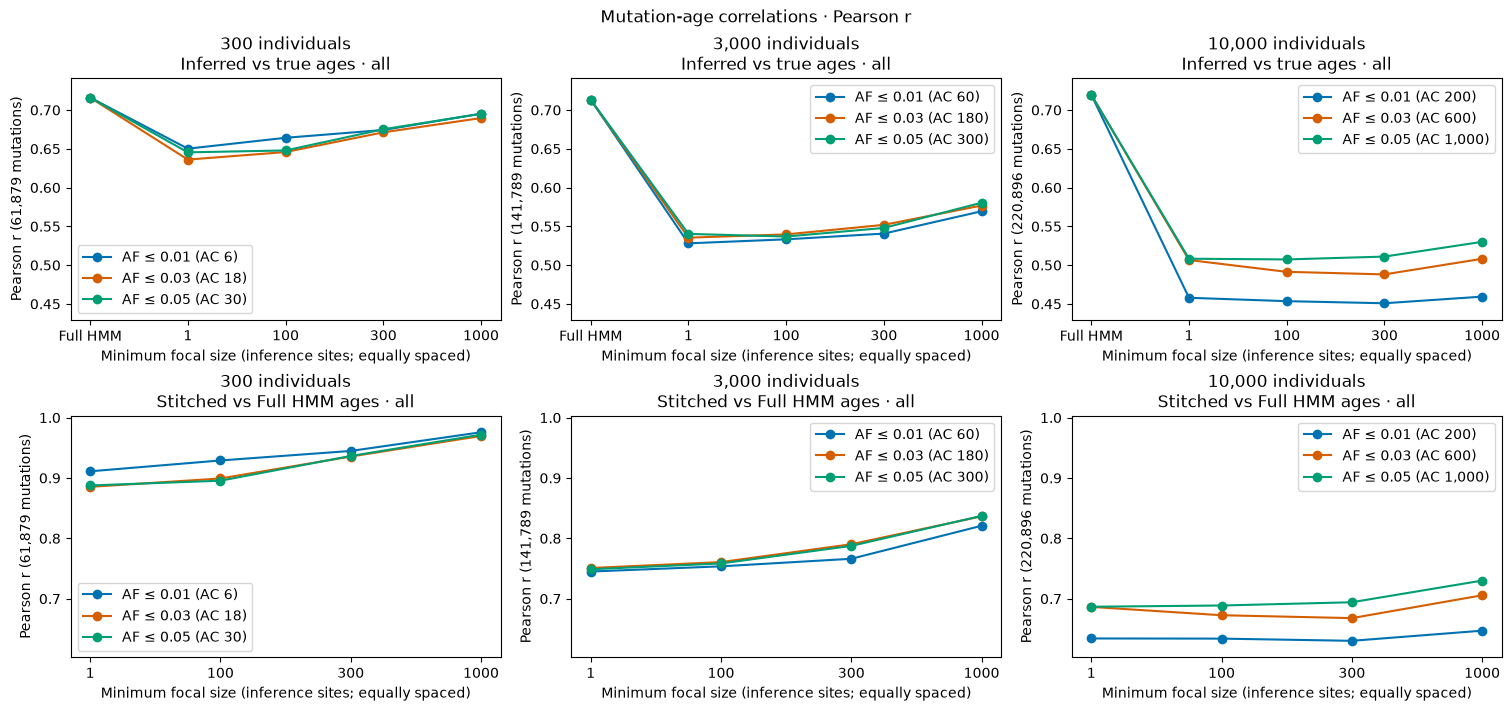

In [6]:
if __name__ == "__main__":
    nb_plot.parameter_grid_save_figure(
        nb_plot.mutation_age_plots(
            age_correlations,
            ["all"],
            cutoff_colors=cutoff_colors,
            datasets=datasets,
            minimum_sizes=minimum_sizes,
            plot_panel_height=3.5,
            plot_panel_width=5,
            plot_range_margin=0.08,
            populations=populations,
            dpi=100,
            show_top_spine=True,
            show_right_spine=True,
        ),
        "mutation_age_correlations",
        output_dir=output_dir,
    )

## Mutation age rank correlations (all mutations)

Spearman ρ uses the same common mutation intersection and cached posterior
ages as Pearson r above, with average ranks for ties. Only the all-mutation
comparison is shown. Reference rows, sample-size columns, AF lines (with AC),
and Full HMM baseline follow the Pearson plots exactly. No trees are redated.

Spearman correlations: out_of_africa_n300_10mbp_error (61879 shared mutations)


Spearman correlations: out_of_africa_n3000_10mbp_error (141789 shared mutations)


Spearman correlations: out_of_africa_n10000_10mbp_error (220896 shared mutations)


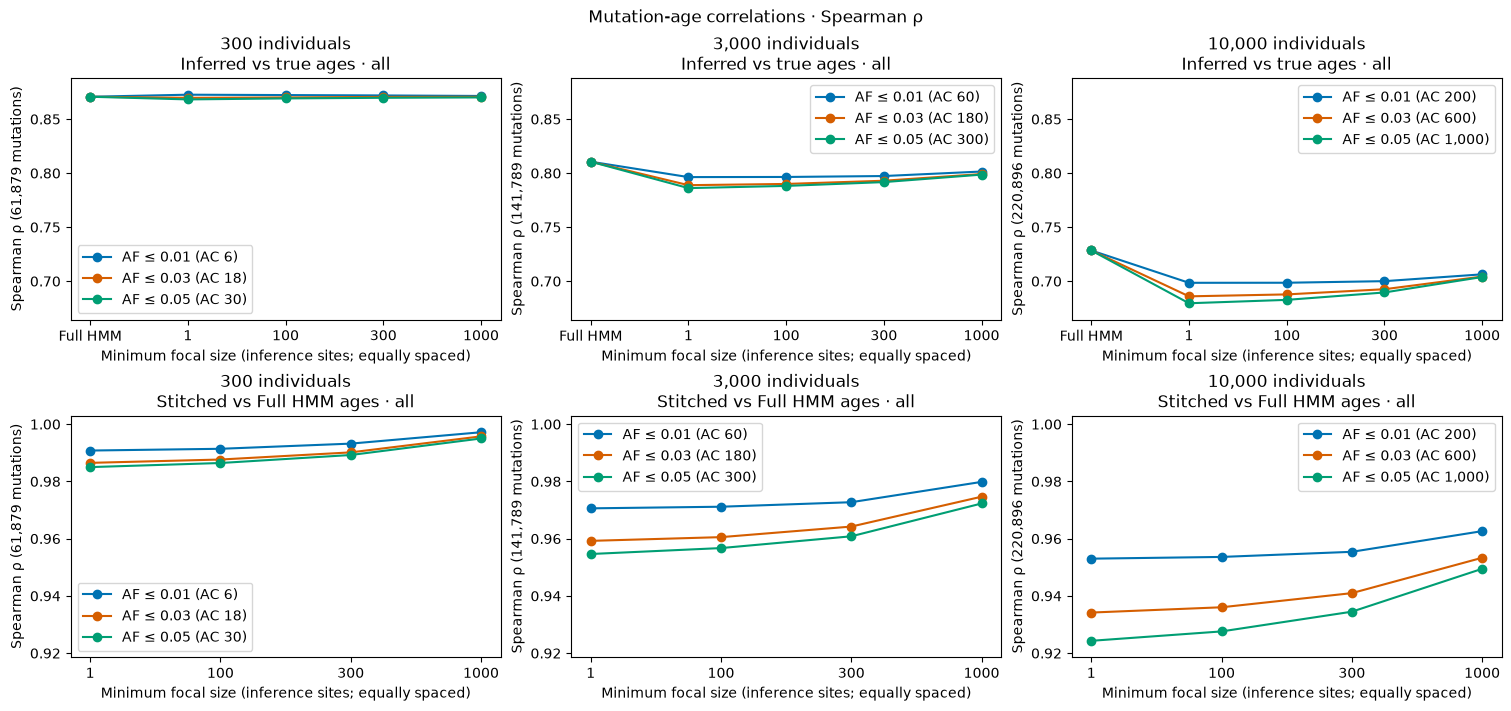

In [7]:
if __name__ == "__main__":
    rank_correlations = nb_utils.all_mutation_rank_correlations(
        config=config, datasets=datasets, output_dir=output_dir
    )
    comparison_keys = grid_keys + [
        "comparison_method",
        "reference_method",
        "frequency_bin",
    ]
    pearson_counts = age_correlations.loc[age_correlations.frequency_bin.eq("all")]
    matched_counts = rank_correlations.merge(
        pearson_counts[comparison_keys + ["matched_mutations"]],
        on=comparison_keys,
        suffixes=("_spearman", "_pearson"),
        validate="one_to_one",
    )
    assert len(matched_counts) == len(rank_correlations) == len(pearson_counts)
    assert matched_counts.matched_mutations_spearman.eq(
        matched_counts.matched_mutations_pearson
    ).all()
    fig = nb_plot.mutation_age_plots(
        rank_correlations,
        ["all"],
        statistic="spearman_rho",
        cutoff_colors=cutoff_colors,
        datasets=datasets,
        minimum_sizes=minimum_sizes,
        plot_panel_height=3.5,
        plot_panel_width=5,
        plot_range_margin=0.08,
        populations=populations,
        dpi=100,
        show_top_spine=True,
        show_right_spine=True,
    )
    nb_plot.parameter_grid_save_figure(
        fig, "mutation_age_spearman_correlations", output_dir=output_dir
    )

## Mutation age correlations by DAF

Fixed derived frequencies come from the dated Full HMM genealogy for the same
common mutation intersection. Frequency bins are DAF < 0.01, 0.01 ≤ DAF < 0.5,
and DAF ≥ 0.5; boundaries enter the upper bin. Each figure repeats the two
reference rows across the three sample-size columns for one DAF bin. Within-bin
correlations can change because the age range is narrower; their values should
be interpreted within a bin. AF cutoffs select seed ancestors; these DAF bins
group mutations for evaluation and are a separate quantity.

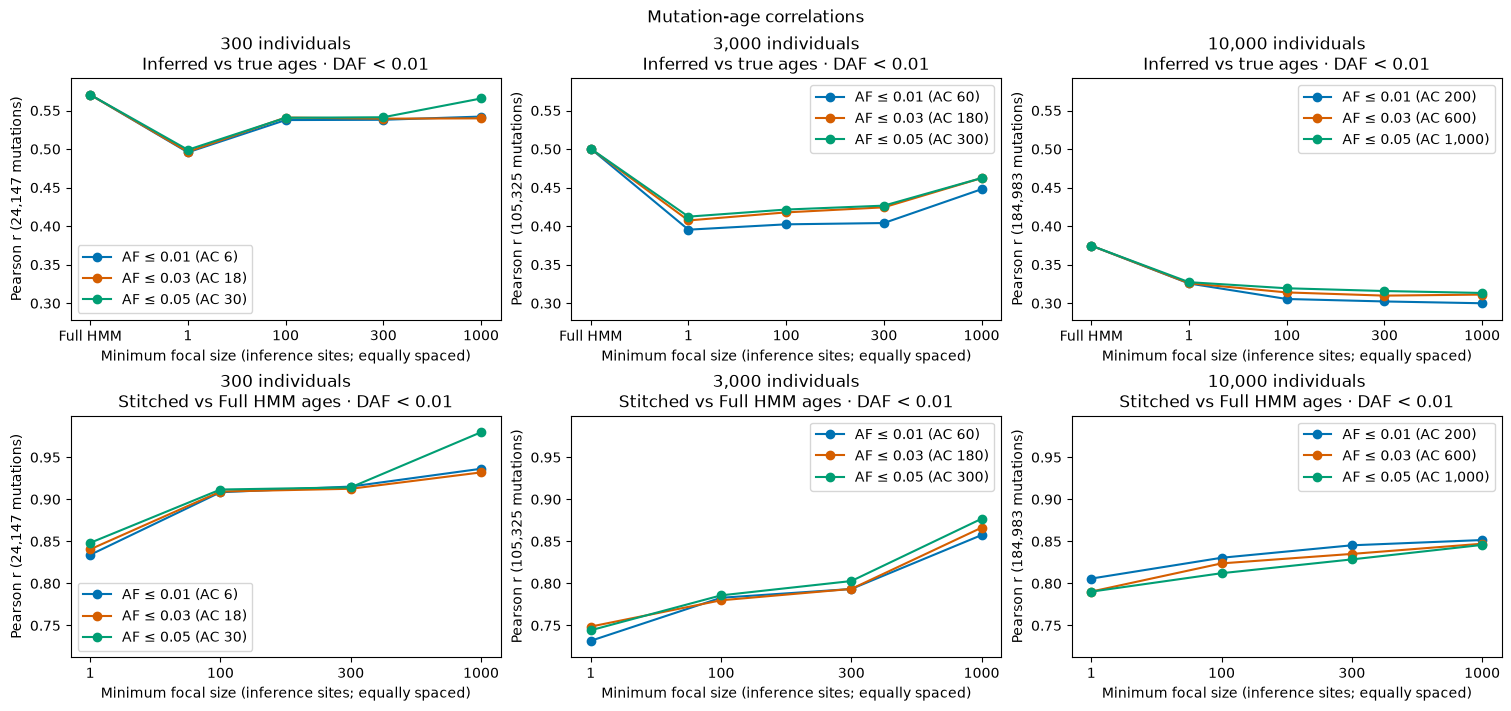

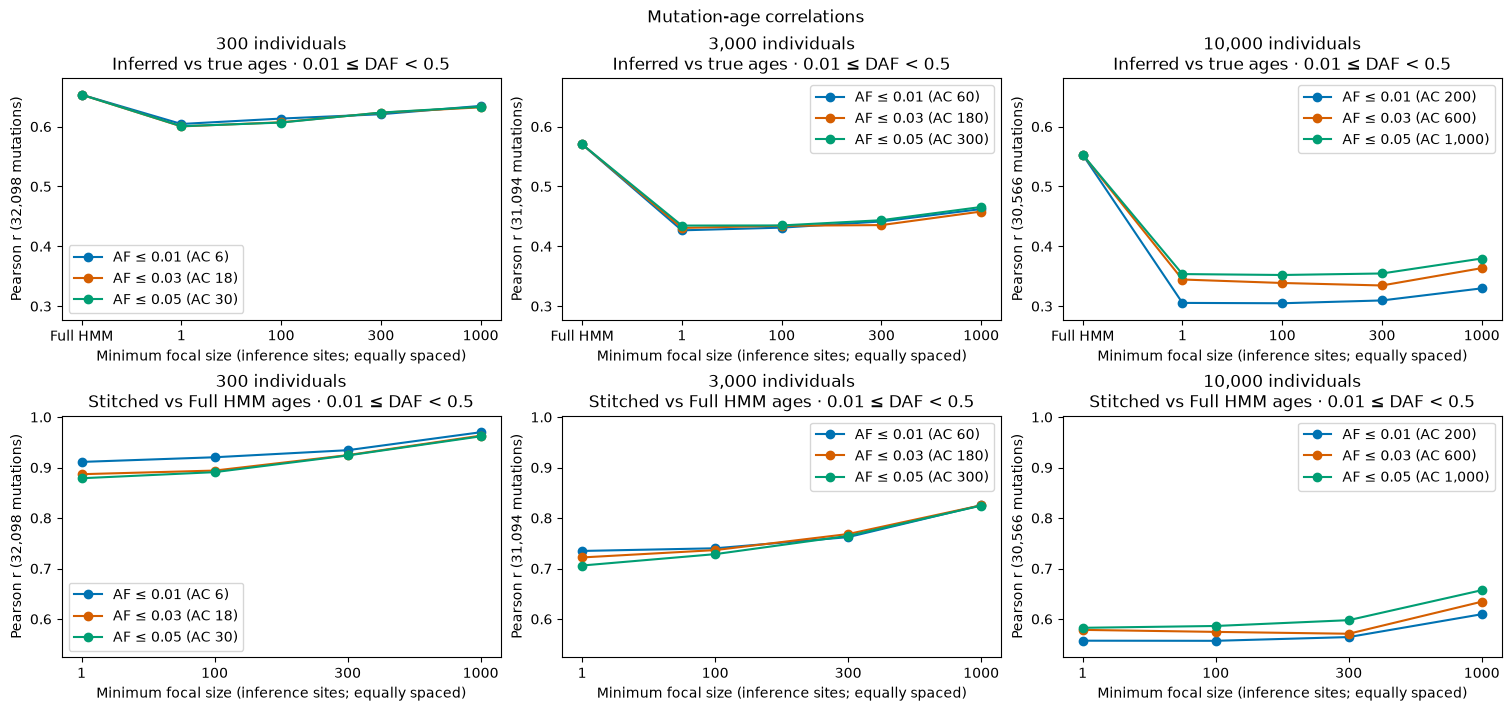

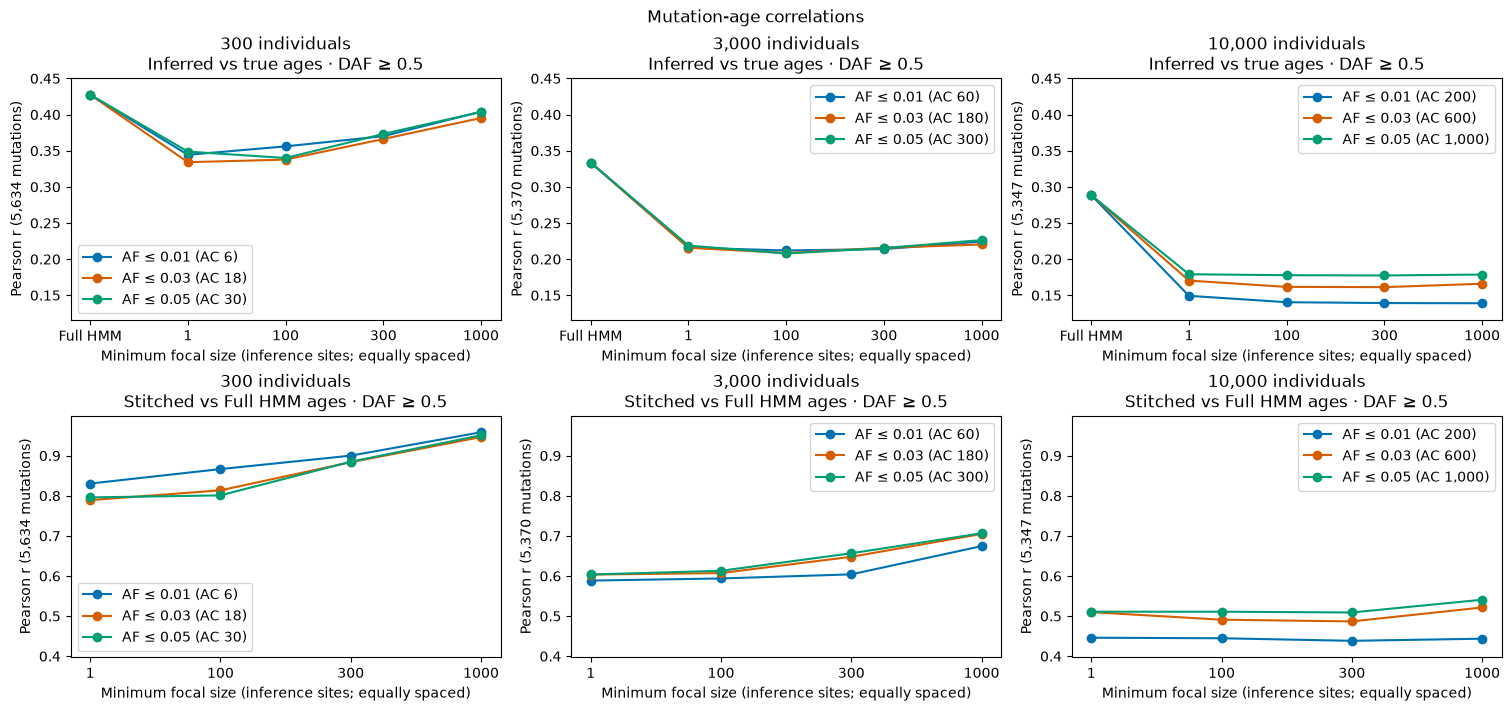

In [16]:
if __name__ == "__main__":
    for index, label in enumerate(config["frequency_bins"]["labels"]):
        nb_plot.parameter_grid_save_figure(
            nb_plot.mutation_age_plots(
                age_correlations,
                [label],
                cutoff_colors=cutoff_colors,
                datasets=datasets,
                minimum_sizes=minimum_sizes,
                plot_panel_height=3.5,
                plot_panel_width=5,
                plot_range_margin=0.08,
                populations=populations,
                dpi=100,
                show_top_spine=True,
                show_right_spine=True,
            ),
            f"mutation_age_daf_{index}",
            output_dir=output_dir,
        )

## Parameter selection for further testing

Combine focal coverage (a work proxy), extra switches, truth ARG metrics and
mutation-age correlations. More agreement with Full HMM is expected as focal
coverage shrinks; the truth metrics are needed to assess whether that change
improves accuracy. Each cohort is one simulation with its own site density,
so equal site-count minima need not represent equal physical distances.
The 300-individual simulation uses seed 2; the two larger simulations use
seed 4. These are not controlled downsamplings or independent replicate sets.
There are no simulation replicate error bars or runtime measurements here.
Larger-cohort topology comparisons are incomplete and are not used to infer
a topology trend across sample sizes. Mutation-age validation is available
across all sample sizes; missing ARG metrics remain NaN in the saved table.

In [17]:
if __name__ == "__main__":
    selection_columns = grid_keys + [
        "switch_increase_percentage_mean",
        "focal_coverage_percentage_mean",
        "focal_agreement_percentage_mean",
        "gap_agreement_percentage_mean",
    ]
    selection = summary[selection_columns].merge(
        tree_metrics, on=grid_keys, how="left", validate="one_to_one"
    )
    ages = age_correlations.loc[
        age_correlations.frequency_bin.eq("all")
        & age_correlations.reference_method.eq("true_arg")
    ]
    selection = selection.merge(
        ages[grid_keys + ["pearson_r", "matched_mutations"]],
        on=grid_keys,
        validate="one_to_one",
    )
    selection.to_csv(output_dir / "parameter_selection.csv", index=False)
    display_columns = selection_columns[:3] + [
        "focal_coverage_percentage_mean",
        "switch_increase_percentage_mean",
        "truth_arf",
        "truth_tpr",
        "pearson_r",
    ]
    ipython_display.display(selection[display_columns].round(5))

,dataset,af_cutoff,min_focal_region_size,focal_coverage_percentage_mean,switch_increase_percentage_mean,truth_arf,truth_tpr,pearson_r
0,out_of_africa_n300_10mbp_error,0.01,1,60.39444,5.59304,0.36718,0.53891,0.65018
1,out_of_africa_n300_10mbp_error,0.01,100,60.04359,4.96004,0.36726,0.53891,0.66420
2,out_of_africa_n300_10mbp_error,0.01,300,57.12562,3.69435,0.36782,0.53831,0.67425
3,out_of_africa_n300_10mbp_error,0.01,1000,37.65282,1.36752,0.36980,0.53509,0.69530
4,out_of_africa_n300_10mbp_error,0.03,1,78.29391,13.64816,0.35988,0.53609,0.63610
5,out_of_africa_n300_10mbp_error,0.03,100,77.71495,11.63134,0.36046,0.53608,0.64584
6,out_of_africa_n300_10mbp_error,0.03,300,73.52494,8.30494,0.36275,0.53566,0.67122
7,out_of_africa_n300_10mbp_error,0.03,1000,50.18192,3.22409,0.36769,0.53348,0.68966
8,out_of_africa_n300_10mbp_error,0.05,1,84.08549,18.05352,0.35666,0.53546,0.64544
9,out_of_africa_n300_10mbp_error,0.05,100,83.39776,14.99660,0.35753,0.53544,0.64789


### Coverage expected for larger minimum sizes

Because minimum size filters whole connected focal components, the minimum-1
length distribution predicts **focal inference-site coverage** at larger
minima without rerunning matching. This is a site-weighted calculation, not
a percentage of regions or physical base-pair coverage. It estimates work
retained, not runtime or accuracy. Candidate sizes are editable in the config.

In [18]:
if __name__ == "__main__":
    predicted_coverage = []
    baseline_lengths = lengths.loc[
        ~lengths.is_gap & lengths.min_focal_region_size.eq(1)
    ]
    for (dataset, cutoff), table in baseline_lengths.groupby(["dataset", "af_cutoff"]):
        baseline = summary.loc[
            summary.dataset.eq(dataset)
            & summary.af_cutoff.eq(cutoff)
            & summary.min_focal_region_size.eq(1)
        ].iloc[0]
        total_sites = baseline.num_haplotypes * baseline.inference_sites_mean
        for minimum in config["followup_minimum_sizes"]:
            retained = table.loc[table.num_sites.ge(minimum)]
            focal_sites = (retained.num_sites * retained["count"]).sum()
            predicted_coverage.append(
                {
                    "dataset": dataset,
                    "af_cutoff": cutoff,
                    "min_focal_region_size": minimum,
                    "predicted_focal_site_coverage_percentage": 100
                    * focal_sites
                    / total_sites,
                }
            )
    predicted_coverage = pd.DataFrame(predicted_coverage)
    predicted_coverage.to_csv(
        output_dir / "predicted_focal_site_coverage.csv", index=False
    )
    ipython_display.display(predicted_coverage.round(2))

,dataset,af_cutoff,min_focal_region_size,predicted_focal_site_coverage_percentage
0,out_of_africa_n10000_10mbp_error,0.01,1000,74.24
1,out_of_africa_n10000_10mbp_error,0.01,2000,65.37
2,out_of_africa_n10000_10mbp_error,0.01,3000,54.85
3,out_of_africa_n10000_10mbp_error,0.01,5000,35.99
4,out_of_africa_n10000_10mbp_error,0.01,10000,11.23
5,out_of_africa_n10000_10mbp_error,0.03,1000,82.84
6,out_of_africa_n10000_10mbp_error,0.03,2000,72.68
7,out_of_africa_n10000_10mbp_error,0.03,3000,61.33
8,out_of_africa_n10000_10mbp_error,0.03,5000,41.26
9,out_of_africa_n10000_10mbp_error,0.03,10000,13.75


### Suggested next tests

**Use `af_cutoff=0.05`, `min_focal_region_size=1000` as the next baseline.**
Minimum 1000 gives the highest overall truth-age correlation among the tested
minima at each AF in the two larger cohorts. At 300 individuals, AF 0.01 and
0.05 at minimum 1000 are effectively tied (r = 0.69530 vs 0.69512). Higher AF
does add switches, but those counts are not a reliable proxy for age accuracy.

| Individuals | Full HMM vs truth, r | AF 0.05 / minimum 1000 vs truth, r |
|---:|---:|---:|
| 300 | 0.71603 | 0.69512 |
| 3,000 | 0.71325 | 0.58047 |
| 10,000 | 0.71978 | 0.53002 |

For the larger cohorts, prioritise **AF 0.03 and 0.05 × minima 1000, 2000,
3000 and 5000**. Keep 1000 as the measured baseline and test whether larger
connected regions recover the substantial remaining age-correlation gap.
AF 0.05 has the highest overall and within-DAF truth-age correlations at
minimum 1000 in both larger cohorts. Retaining AF 0.03 tests the trade-off
between seed-extension cost and HMM work; runtime was not measured here.
The higher minima are candidates for validation, not measured age improvements.

At AF 0.05, minimum 3000 is predicted to retain about **49% / 64%** focal
inference-site coverage for 3,000 / 10,000 individuals. Minimum 10,000 retains
only **7% / 15%**, so the 2000–5000 range is a more useful first search for
balancing coverage and accuracy. At 300 individuals, minimum 3000 retains
only about 15% focal sites, so keep minimum 1000 as the main small-cohort case.

The deterioration at large sample sizes is also visible within the fixed DAF
bins. At 10,000 individuals and AF 0.05/minimum 1000, truth-age r is 0.313,
0.380 and 0.179 across the three bins, compared with Full HMM's 0.375, 0.553
and 0.288. This is not solely a change in the mixture of mutation frequencies.
There is also a trade-off within the largest cohort: at AF 0.05, rare-variant
truth-age r falls from 0.327 at minimum 1 to 0.313 at minimum 1000 even though
overall r improves. Keep **AF 0.05 / minimum 1 as one additional control at
10,000 individuals** when testing larger minima, and judge the DAF panels
alongside the overall correlation rather than optimising only the latter.
Pearson r measures association, not age calibration: the cached correlation
table also includes median absolute errors and mean bias. For example, median
absolute error at 10,000 individuals is 87.3 generations for this stitched
setting and 85.5 for Full HMM, despite the larger correlation difference.

The small-cohort ARG metrics show a separate trade-off: larger minima improve
age correlations while moving topology scores toward Full HMM. The incomplete
larger-cohort ARG results do not establish how that topology trade-off scales.
Treat these settings as candidates from one simulation per cohort; confirm
age accuracy and runtime in follow-up runs and additional simulation seeds.